# Experiment 21: NMR head only learning curve and parity

Five training-set sizes, validation-selected checkpoints, and matched validation/test evaluation.

Analysis date: 29 October 2026.

In [ ]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path('/Users/louismcauliffe/code/research/NequIP_experiments')
DATA = ROOT / 'experiments/21-23-LearningCurve-data'
FIG = ROOT / 'experiments/21-23-LearningCurve-figures'
metrics = pd.read_csv(DATA / 'metrics.csv')
manifest = json.loads((DATA / 'manifest.json').read_text())
assert metrics.export_matches_checkpoint.all()
valid = metrics.query("split == 'valid'")
np.testing.assert_allclose(valid.loss, valid.saved_valid_loss, rtol=1e-3, atol=1e-7)
for split in ('valid', 'test'):
    path = ROOT / f'data/nmr_iso/{split}.xyz'
    assert hashlib.sha256(path.read_bytes()).hexdigest() == manifest['input_sha256'][str(path)]
print('26 audited checkpoints: 25 primary models and one separate ELoRA pilot.')


In [ ]:
results = metrics.query('experiment == 21 and primary and split == "test"').sort_values(['n', 'experiment'])
display(results[['experiment', 'n', 'Si_rmse', 'O_rmse', 'loss', 'best_epoch', 'final_epoch', 'status', 'trainable_parameters']].reset_index(drop=True))

experiment,n,Si_rmse,O_rmse,loss,best_epoch,final_epoch,status,trainable_parameters
21,10,4.0992,9.1844,0.22319,4704,5004,Early stopping,132
21,50,3.097,7.4263,0.1369,5361,5661,Early stopping,132
21,100,3.0239,7.1708,0.12894,3618,3918,Early stopping,132
21,200,2.9822,7.0696,0.12536,2676,2976,Early stopping,132
21,800,2.8718,6.7519,0.11522,1697,1997,Early stopping,132


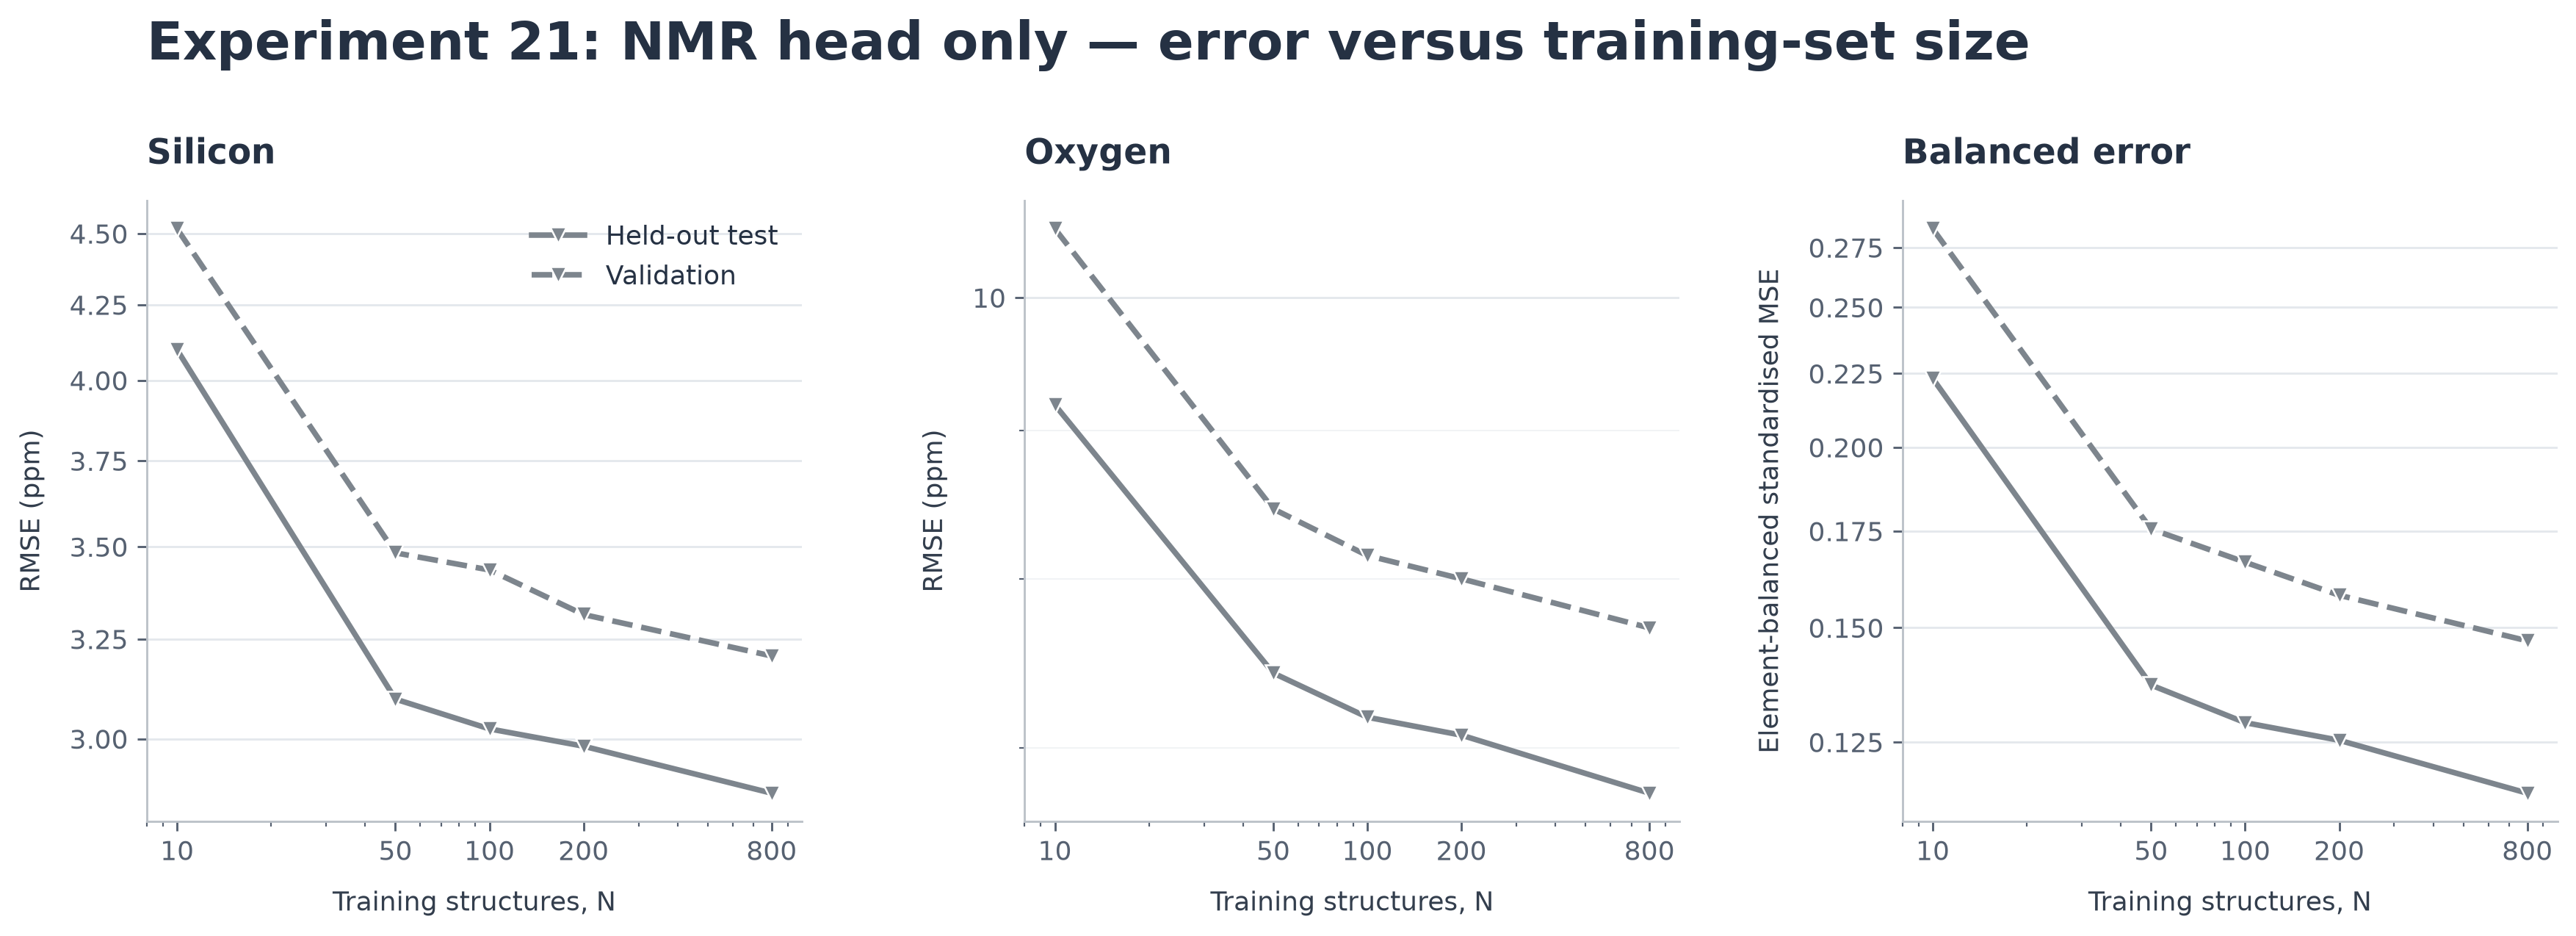

In [ ]:
display(Image(filename=str(FIG / '21-learning-curve-log-log.png')))

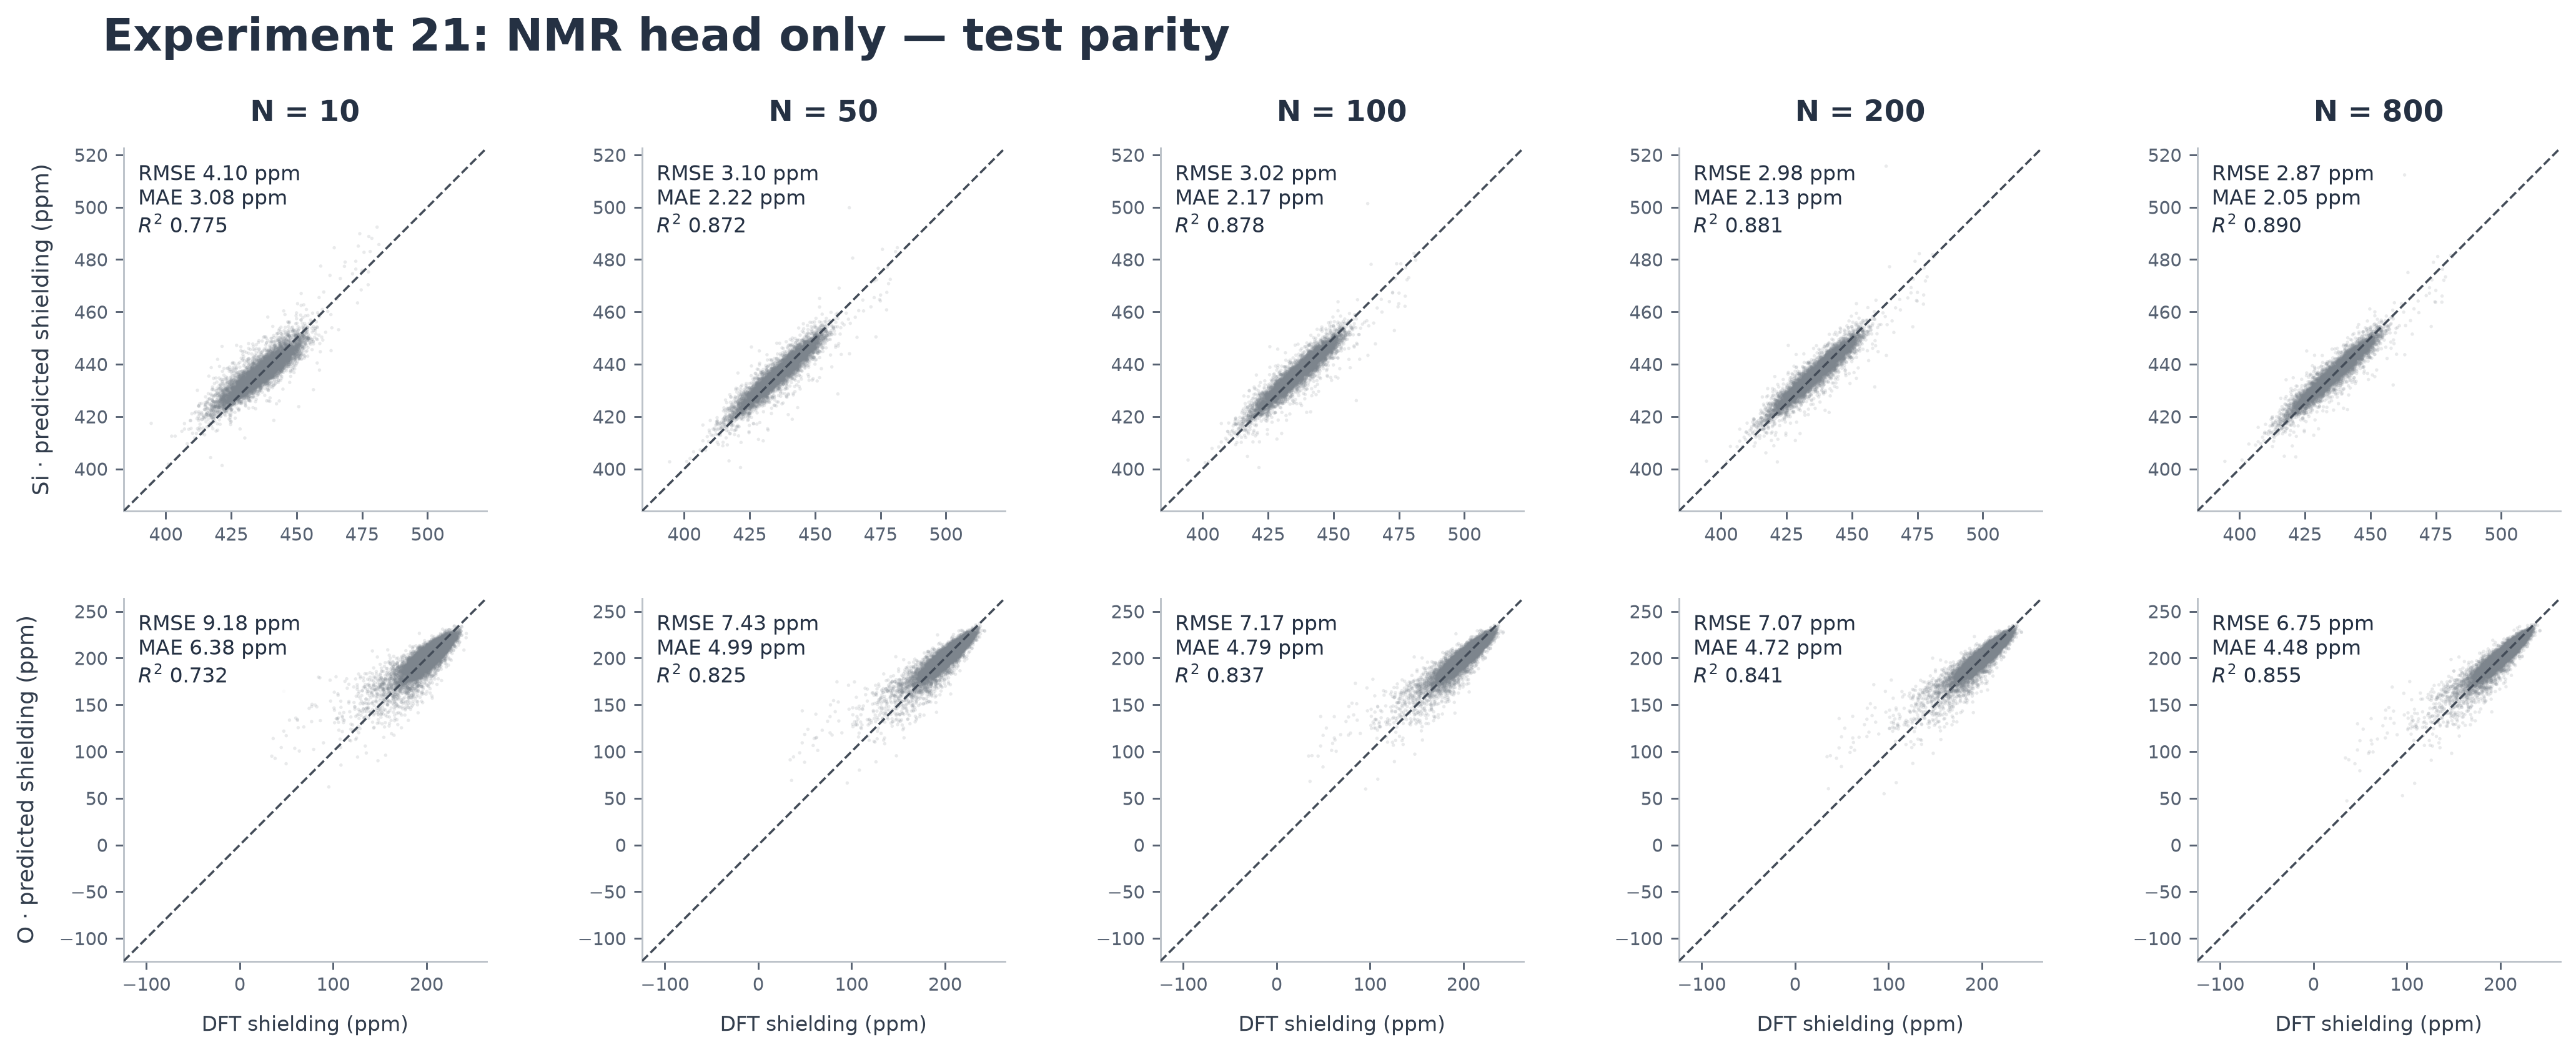

In [ ]:
display(Image(filename=str(FIG / '21-test-parity.png')))

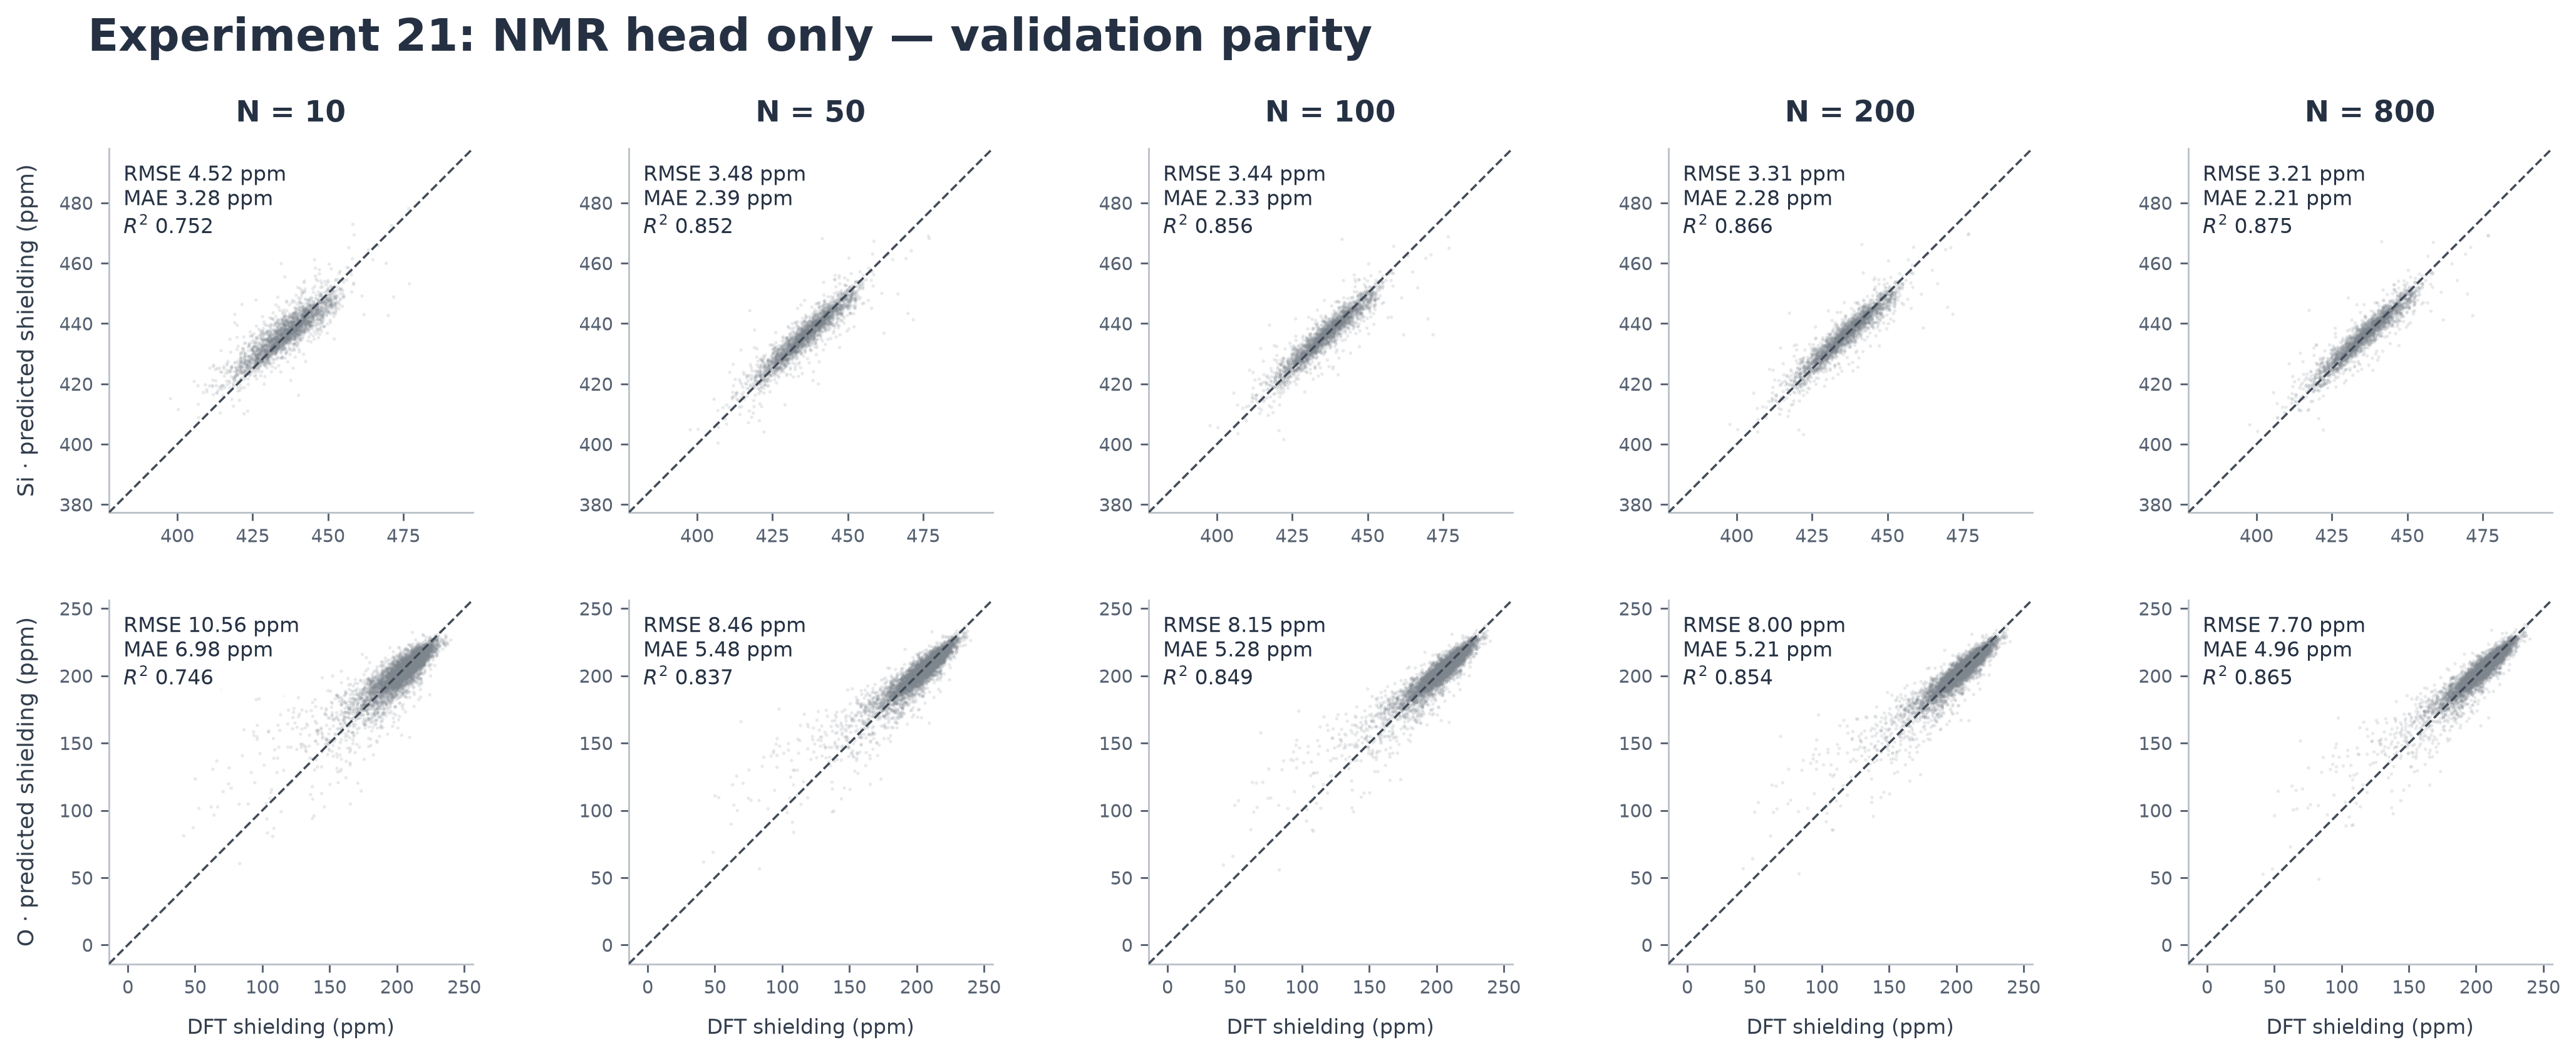

In [ ]:
display(Image(filename=str(FIG / '21-valid-parity.png')))

## Reading these results

- **Test curves** use the same 150 held-out structures; **validation curves** use the same 50 structures used for checkpoint selection.
- Each checkpoint minimises validation loss. The test set is not used to choose checkpoints or to choose between the two ELoRA N=100 runs.
- N is the number of training structures: 10, 50, 100, 200, 800. All methods use the same seed-42 nested subsets. The 50 validation structures are additional labelled data.
- Silicon and oxygen RMSE are in **ppm of absolute isotropic shielding**, not referenced chemical shift. Balanced error is `0.5 * [(Si RMSE / 8.789599019755547)^2 + (O RMSE / 19.197689920683118)^2]`.
- Both learning-curve axes are logarithmic. Lines connect measurements; they are not fitted scaling laws. Parity axes are linear, with a dashed identity line and identical per-element limits across methods and sizes.
- The methods have different learning rates, trainable parameter counts and stopping budgets. These results compare the specified training procedures, not an exhaustive optimisation of each method.
- One sweep per method, seed 42: no across-seed error bars or statistical superiority claims. The earlier ELoRA N=100 pilot uses the same seed and is not an independent replicate.
- **ELoRA N=800 is treated as converged**, following the researcher's assessment that learning-rate decay had made further meaningful improvement unlikely. The best checkpoint is epoch 301; the saved run ends at epoch 577, with 276 of 300 checks since best. The audit distinguishes this convergence assessment from formal early-stopping termination.
- NMR head only means the improved Experiment 21, including its trained readout, scales and offsets. The original unfinished Experiment 18 is not one of the five primary curves.

## Reproduce

The full data, checkpoint hashes, run status, predictions and metrics are in `21-23-LearningCurve-data/`.
Run `evaluate.py` there with the project Python environment to repeat evaluation; its `NMR_COMPARISON_OUTPUT` environment variable selects an alternative output directory.
Run `analysis_helpers/learning_curve_comparison.py` to regenerate every PNG, PDF and SVG from the saved evaluation data.
Historical evaluation manifests retain their original paths; `21-23-LearningCurve-data/relocations.json` maps the moved folders.
